<a href="https://colab.research.google.com/github/moushi21/microduck_rl/blob/develop/Microduck_Walk2Run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

１．uvのインストールとリポジトリの取得を開始します。

Colabのランタイムタイプは、L4を選択してください。

In [ ]:
# 1. uv のインストールとリポジトリの取得
!pip install uv
!git clone https://github.com/moushi21/microduck_rl.git
%cd microduck_rl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 184.9 MB/s  0:00:00
Cloning into 'microduck_rl'...
remote: Enumerating objects: 9632, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 9632 (delta 22), reused 23 (delta 18), pack-reused 9601 (from 2)
Receiving objects: 100% (9632/9632), 38.60 MiB | 19.48 MiB/s, done.
Resolving deltas: 100% (6610/6610), done.
/content/microduck_rl


２．依存関係のセットアップ（PyTorch CUDA対応）

In [ ]:
# 2. 依存関係のセットアップ (PyTorch CUDA対応)
!uv pip install --system torch torchvision --index-url https://download.pytorch.org/whl/cu121
!uv pip install --system -e .

Using Python 3.13.16 environment at: /usr
Checked 2 packages in 113ms
Using Python 3.13.16 environment at: /usr
Resolved 133 packages in 1.38s
Prepared 54 packages in 33.94s
Uninstalled 17 packages in 704ms
Installed 54 packages in 217ms
 + bcrypt==5.0.0
 + better-actuator-models==1.0.1 (from git+https://github.com/Rhoban/bam.git@57d13ead53206a6bf0db3d66f86506ae8c2ce01a)
 + colorama==0.4.6
 - decorator==4.4.2
 + decorator==5.3.1
 + deprecated==3.0.0
 + fabric==3.2.3
 + gitdb==4.0.12
 + gitpython==3.2.1
 + glfw==2.11.0
 + invoke==2.2.1
 + jedi==0.20.1
 - matplotlib==3.10.0
 + matplotlib==3.11.2
 + mediapy==1.2.7
 + mjlab==1.3.0
 + mjlab-microduck==0.1.0 (from file:///content/microduck_rl)
 + mjviser==0.0.14
 + msgspec==0.22.0
 + mujoco==3.17.0
 + mujoco-warp==3.8.1
 - nvidia-cublas-cu12==12.9.2.10
 + nvidia-cublas-cu12==12.8.4.1
 - nvidia-cuda-cupti-cu12==12.9.79
 + nvidia-cuda-cupti-cu12==12.8.90
 - nvidia-cuda-nvrtc-cu12==12.9.86
 + nvidia-cuda-nvrtc-cu12==12.8.93
 - nvidia-cuda-runti

３．追加タスクした「Mjlab-Run-Flat-MicroDuck」を確認

In [ ]:
!uv sync
!uv run list-envs

Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: .venv
Resolved 154 packages in 1ms
Prepared 116 packages in 11.42s
Installed 142 packages in 341ms
 + absl-py==2.3.1
 + annotated-doc==0.0.4
 + annotated-types==0.7.0
 + anyio==4.12.1
 + asttokens==3.0.1
 + bcrypt==5.0.0
 + better-actuator-models==1.0.1 (from git+https://github.com/Rhoban/bam.git@62bd8ce12154340be97e06f7f41a0ca8f116d967)
 + certifi==2026.1.4
 + cffi==2.0.0
 + charset-normalizer==3.4.4
 + click==8.3.1
 + cloudpickle==3.1.2
 + colorama==0.4.6
 + contourpy==1.3.3
 + cryptography==46.0.3
 + cycler==0.12.1
 + decorator==5.2.1
 + deprecated==1.3.1
 + docstring-parser==0.17.0
 + etils==1.13.0
 + executing==2.2.1
 + fabric==3.2.2
 + filelock==3.20.3
 + flatbuffers==25.12.19
 + fonttools==4.63.0
 + fsspec==2026.1.0
 + gitdb==4.0.12
 + gitpython==3.1.46
 + glfw==2.10.0
 + grpcio==1.76.0
 + h11==0.16.0
 + hf-xet==1.5.0
 + httpcore==1.0.9
 + httpx==0.28.1
 + huggingface-hub==1.15.0
 + idna==3

４．ColabのシークレットからWANDB_API_KEYを取得し、wandbログイン

In [ ]:
# 4. Colab のシークレットから WANDB_API_KEY を取得し、学習を実行
import os, wandb
from google.colab import userdata

try:
    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
except userdata.SecretNotFoundError:
    print("エラー: Colabのシークレット(左メニューの🔑アイコン)に 'WANDB_API_KEY' が登録されていません。")

wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: moushi21 (moushi21-dynasoft-corp-) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

５．【学習】タスクMjlab-Velocity-Flat-MicroDuckを8445イテレーション学習したチェックポイントをベースに、スモークテストを実施する

In [ ]:
%env MICRODUCK_WARM_START=1
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 64 \
  --agent.resume True \
  --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/2zkaxzn9 \
  --wandb-checkpoint-name model_5500.pt \
  --agent.max_iterations 5

env: MICRODUCK_WARM_START=1
[mdp] Patches 1-2 active: NaN-safe reward/advantage
[mdp] Patch 4 active: ONNX export filters passive_* joints
[mdp] Patch 5 active: MICRODUCK_WARM_START=1 restarts curricula after checkpoint load
/content/microduck_rl/.venv/lib/python3.12/site-packages/tyro/_parsers.py:353: UserWarning: The field `env.scene.entities.robot.collisions.0.geom-names-expr` is annotated with type `tuple[str, ...]`, but the default value `['.*_collision']` has type `<class 'list'>`. We'll try to handle this gracefully, but it may cause unexpected behavior.
  warnings.warn(message)
/content/microduck_rl/.venv/lib/python3.12/site-packages/tyro/_resolver.py:600: TyroWarning: <class 'list'> does not match any type in Union: [<class 'str'>, <class 'tuple'>, <class 'NoneType'>]
  warnings.warn(
[INFO] Training with: device=cuda:0, seed=42, rank=0
[INFO] Logging experiment in directory: logs/rsl_rl/run/2026-10-24_12-55-41_run
Setting seed: 42
Warp 1.12.0 initialized:
   CUDA Toolkit 12.9

６．【学習１回目】X Linear Velocity(0.0, 0.4)にて、1000イテレーションの学習効果を確認

In [ ]:
%env MICRODUCK_WARM_START=1 # Mjlab-Velocity-Flat-MicroDuckタスクからの重み引き継ぎ
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume True \
  --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/2zkaxzn9 \
  --wandb-checkpoint-name model_5500.pt \
  --agent.max_iterations 1000 > /dev/null 2>&1

env: MICRODUCK_WARM_START=1


７．【学習２回目】1000イテレーションの追加学習効果を確認

In [ ]:
%env MICRODUCK_WARM_START=0 # 学習１回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume True \
  --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/n2hejfbp \
  --wandb-checkpoint-name model_999.pt \
  --agent.max_iterations 1000 > /dev/null 2>&1

env: MICRODUCK_WARM_START=0 # 学習１回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ


８．【学習３回目】課題：ふらつきが大きい。対策：追加1000イテレーションの学習効果を確認

In [ ]:
%env MICRODUCK_WARM_START=0 # 学習２回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume True \
  --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/u67rjxw6 \
  --wandb-checkpoint-name model_999.pt \
  --agent.max_iterations 1000 > /dev/null 2>&1

env: MICRODUCK_WARM_START=0 # 学習２回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ


９．【学習４回目】X Linear Velocity(0.0, 0.45）にて、4000イテレーションの学習効果を確認

In [ ]:
%env MICRODUCK_WARM_START=0 # 学習３回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume True \
  --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/lxzksu6v \
  --wandb-checkpoint-name model_999.pt \
  --agent.max_iterations 4000 > /dev/null 2>&1

env: MICRODUCK_WARM_START=0 # 学習２回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ


１０．【学習５回目】X Linear Velocity(0.0, 0.5）にて、5000イテレーションの学習効果を確認

In [ ]:
%env MICRODUCK_WARM_START=0 # 学習４回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume True \
  --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/m4cta92r \
  --wandb-checkpoint-name model_3999.pt \
  --agent.max_iterations 5000 > /dev/null 2>&1

env: MICRODUCK_WARM_START=0 # 学習４回目のMjlab-Run-Flat-MicroDuckタスクからの重み引き継ぎ


４．MicroDuckの歩行タスクを学習します。

（１）学習のデフォルトは、50,000iteration、並列学習はパラメータとして、4096体としています。

（２）wandbとの接続を正常に行うため、ログ出力モードを実行後し、ログが大量に出力されるので、一旦停止後、再度ログを、/dev/nullに捨てるモードを実行してください。進捗状況は、wandbにて確認を行います。

（３）wandbによる進捗状況の確認手段としては、強化学習の学習ストラテジーである、カリキュラム学習のログが目安となります。2,000iteration(step)を超えると、他のカリキュラム項目もクリアしていますので、学習を停止しても問題ありません。

（４）シミュレータMjlabにて、安定した動作を得るためには、学習時間の目安としては、３〜４時間程度は必要となります。
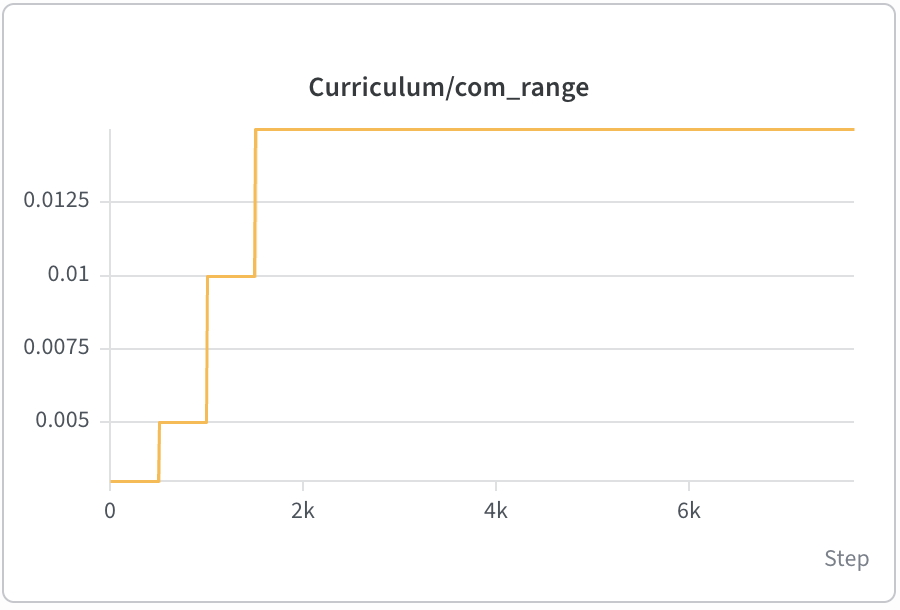

前進速度を 学習時の0〜0.4 m/sの間から選ぶ設定「command.ranges.lin_vel_x = (0.0, 0.4)」を、推論時(run play)に、両方を 0.4 設定。前進速度がランダムに変わらず、毎回 前進目標が0.4 m/s になります。「command.ranges.lin_vel_x = (0.4, 0.4)」

In [ ]:
%cd /content/microduck_rl
!git pull origin develop
!uv sync

/content/microduck_rl
remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 508 bytes | 254.00 KiB/s, done.
From https://github.com/moushi21/microduck_rl
 * branch            develop    -> FETCH_HEAD
   c518d22..8d89d7e  develop    -> origin/develop
Updating c518d22..8d89d7e
Fast-forward
 src/mjlab_microduck/tasks/microduck_run_env_cfg.py | 1 +
 1 file changed, 1 insertion(+)
Resolved 154 packages in 1ms
Checked 142 packages in 1ms


５．【推論】wandbの該当ランID（例：pg0bh5k9）を指定し、動画ファイルを生成します。内部詳細の実行手順は以下の通り

（１）wandbチェックポイントの取得

（２）61次元のObservationを元に、シミュレーションでの推論

（３）動画レンダリング

※注意：タスクが複雑であれば、録画時間も長めにする必要があります。1分以上の録画を行う場合は、約１時間は必要となります。（１時間経過した後に停止してください。）

In [ ]:
import os

# GPU描画環境変数の設定
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

# ViserのGUIエラーを回避するため、--viewer native と xvfb-run を用いてヘッドレスで実行し、動画を作成します
!xvfb-run --auto-servernum --server-args="-screen 0 1280x720x24" uv run play Mjlab-Run-Flat-MicroDuck --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/c8rdj7t6 --num-envs 1 --video True --video-width 1280 --video-height 720 --video-length 1000 --viewer native

[mdp] Patches 1-2 active: NaN-safe reward/advantage
[mdp] Patch 4 active: ONNX export filters passive_* joints
[mdp] Patch 5 active: MICRODUCK_WARM_START=1 restarts curricula after checkpoint load
wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
[INFO]: Loading checkpoint: model_4999.pt (run: c8rdj7t6, downloaded)
/content/microduck_rl/.venv/lib/python3.12/site-packages/mjlab/entity/entity.py:149: UserWarning: Actuator config matched 14 joint(s) but the same expressions also match 7 site(s): imu, left_foot, head_camera, tof, head_imu, mouth_tip, right_foot. Add a separate config with transmission_type=TransmissionType.SITE if those should be actuated too.
  self._add_actuators()
Warp 1.12.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA L4" (22 GiB, sm_89, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.12.0
Warp DeprecationWarning: The symbol `warp.context.runtime` will soon

６．【推論】ビデオを再生します。

※注意：タスク毎に、mp4ファイルが出力される場所が、異なる場合があります。logs/rsl_rlディレクトリ内を検索し、video_pathを設定の上、再生してください。

In [ ]:
import os
from IPython.display import HTML
from base64 import b64encode

# 動画ファイルの正確な保存先
video_path = "logs/rsl_rl/run/wandb_checkpoints/c8rdj7t6/videos/play/rl-video-step-0.mp4"

if os.path.exists(video_path):
    print(f"動画を読み込み中: {video_path}")
    mp4_data = b64encode(open(video_path, 'rb').read()).decode()
    display(HTML(f'<video width="640" height="480" controls><source src="data:video/mp4;base64,{mp4_data}" type="video/mp4"></video>'))
    # display(HTML(f'<video width="1024" height="768" controls><source src="data:video/mp4;base64,{mp4_data}" type="video/mp4"></video>'))
else:
    print(f"動画ファイルが見つかりません。作成用セルが正常に終了したか確認してください。パス: {video_path}")

動画を読み込み中: logs/rsl_rl/run/wandb_checkpoints/c8rdj7t6/videos/play/rl-video-step-0.mp4
